# Bosch date data: join integrity, timestamp quality and chronological validation

A separate second phase of the [numeric investigation](explore.ipynb). This notebook reads `train_date.csv` and streams numeric measurement counts from `train_numeric.csv`; it does not modify the numeric baseline or its archived results.

**Decision:** assess whether the files can be joined safely, what recorded time ranges reveal, and how a declared random-versus-chronological experiment behaves. All results are exploratory. The dataset has already informed historical modeling decisions; sorting it by time cannot create a new independent holdout.

**Meaning of time:** supplied numeric timestamp units and calendar origin are not established here. Keep float64 values, report “dataset time units,” and do not convert to dates, hours or seconds. Earliest/latest records are not confirmed arrival/completion times; their difference is a **recorded time span**, not measured processing duration.

## 1. Scope and fixed experiment

Use a 10,000-row chunk to bound wide-table memory. Retain only 51 numeric count features, compact date summaries and aggregate quality profiles. `BOSCH_DATE_NROWS=0` (default) scans both full files; a positive value reads the first N rows of each file for a smoke test. Prefixes are not random samples, and a partial join audit cannot certify the full files. A file with reordered rows can also produce unmatched IDs in a prefix check even if full files match.

The model comparison is a small, predeclared **end-of-record screening** experiment: fixed HGB settings, numeric counts versus counts plus five global date summaries. The historically selected four stations below are retained only for timing diagnostics, not model feature selection. S32_only retains its numeric definition and is not a predictor in this experiment.

Earliest/latest timestamps, time span and route counts require all the records used to compute them. **Do not use them for an earlier prediction point.** Even end-of-record usage requires process confirmation that these records exist before the target is known.

In [1]:
import gc
import hashlib
import json
import os
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from bosch import gains_curve, resolve_data_path
from bosch_dates import (
    FOCUS_STATIONS, audit_join, chronological_split, random_split_same_cohort,
    read_date_summary, read_numeric_counts, run_date_experiment,
)

ROOT = Path.cwd()
if not (ROOT / 'bosch_dates.py').is_file():
    raise RuntimeError('Run from the Bosch project directory.')
N_ROWS = int(os.environ.get('BOSCH_DATE_NROWS', '0')) or None
CHUNK_SIZE = int(os.environ.get('BOSCH_DATE_CHUNKSIZE', '10000'))
if (N_ROWS is not None and N_ROWS < 1) or CHUNK_SIZE < 1:
    raise ValueError('Use nonnegative NROWS and positive CHUNKSIZE.')
SEED = 42
NUMERIC_PATH = resolve_data_path(os.environ.get('BOSCH_DATA_PATH'))
DATE_PATH = Path(os.environ.get('BOSCH_DATE_PATH', str(NUMERIC_PATH.with_name('train_date.csv'))))
if not DATE_PATH.is_file():
    raise FileNotFoundError(f'Date CSV not found: {DATE_PATH}')
DATE_PATH = DATE_PATH.resolve()
SCOPE = 'full local numeric and date files' if N_ROWS is None else f'prefix smoke test: first {N_ROWS:,} rows of each file'
RUN_ID = 'dates_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = ROOT / 'artifacts' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
MODEL_PARAMETERS = dict(max_iter=100, max_leaf_nodes=15, learning_rate=0.1,
                        class_weight='balanced', early_stopping=False, random_state=SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('EXECUTED SCOPE:', SCOPE)
print('Chunk size:', CHUNK_SIZE)
print('Fixed HGB parameters:', MODEL_PARAMETERS)
print('Artifacts:', RUN_DIR.relative_to(ROOT))

EXECUTED SCOPE: full local numeric and date files
Chunk size: 10000
Fixed HGB parameters: {'max_iter': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'class_weight': 'balanced', 'early_stopping': False, 'random_state': 42}
Artifacts: artifacts/dates_20261029T140103667151Z


## 2. Load and audit identities before joining

The date scanner preserves blank values as NaN and recorded zeros as valid observations. It rejects infinite timestamps and duplicate IDs, including duplicates across chunk boundaries. Duplicate headers are rejected before Pandas can rename them. Negative/zero values are counted for review, not automatically removed. Numeric sensors retain float32; date values stay float64 to avoid coalescing distinct timestamps through float32 rounding.

Only compact summaries survive each chunk. The merge is validated one-to-one and preserves **every numeric row** in source order. Unmatched numeric IDs, extra date IDs and matched rows whose timestamps are all missing are distinct cases. No silent deduplication or inner-join row loss is permitted.

In [2]:
date_parts, date_profile, station_quality, date_schema = read_date_summary(
    DATE_PATH, chunksize=CHUNK_SIZE, nrows=N_ROWS)
print('Date scan complete:', len(date_parts), 'parts;', len(date_schema), 'date columns')
numeric_parts, numeric_schema = read_numeric_counts(NUMERIC_PATH, chunksize=CHUNK_SIZE, nrows=N_ROWS)
parts, join_audit, numeric_only_ids, date_only_ids = audit_join(numeric_parts, date_parts)
print('Numeric scan and join complete')
display(pd.Series(join_audit, name='count').to_frame())
print('Retained compact joined frame GiB:', parts.memory_usage(deep=True).sum() / 1024**3)
np.savez_compressed(RUN_DIR / 'unmatched_ids.npz', numeric_only=numeric_only_ids, date_only=date_only_ids)
date_profile.to_csv(RUN_DIR / 'date_column_profile.csv', index=False)
station_quality.to_csv(RUN_DIR / 'date_station_quality.csv')
del numeric_parts, date_parts
gc.collect()

Date scan complete: 1183747 parts; 1156 date columns


Numeric scan and join complete


,count
numeric_rows,1183747
date_rows,1183747
matched_ids,1183747
numeric_only_ids,0
date_only_ids,0
joined_rows,1183747
matched_but_all_dates_missing,582


Retained compact joined frame GiB: 0.22490024380385876


0

## 3. Timestamp missingness and recorded ranges

All statistics in this section describe the executed scope above. No target labels determine these checks. All-missing rows retain NaN for first/last/span and zero recorded counts; they are never assigned time zero. A single unique recorded timestamp gives span zero, which is different from an unknown span.

Station identifiers do not establish process order. Multiple times within a station can reflect measurement sequence, elapsed time, rework or another process. They are a diagnostic, not a confirmed defect in the source.

,value
date_columns,1.156000e+03
mean_column_missing_fraction,8.224362e-01
columns_all_missing,0.000000e+00
zero_timestamp_cells,1.200000e+01
negative_timestamp_cells,0.000000e+00
numeric_parts_without_known_time,5.820000e+02
parts_with_zero_recorded_span,1.200000e+02
parts_with_positive_recorded_span,1.183045e+06


,count,mean,std,min,1%,25%,50%,75%,99%,max
date_first,1183165.0,848.414650,468.974041,0.00,11.92,466.82,877.71,1238.14,1666.98,1716.54
date_last,1183165.0,859.133075,468.339241,0.46,14.93,491.36,887.39,1240.36,1668.92,1718.48
date_span,1183165.0,10.718424,17.015375,0.00,0.31,1.71,3.70,11.77,62.95,699.20
date_measurement_count,1183747.0,205.263777,32.130669,0.00,120.00,178.00,207.00,233.00,262.00,399.00
date_station_count,1183747.0,12.149689,2.410047,0.00,7.00,13.00,13.00,13.00,16.00,23.00


,parts_recorded,parts_with_multiple_records,parts_with_positive_range,coverage
station,,,,
L3_S32,24543,0,0,0.020733
L3_S33,1114695,1114695,0,0.941667
L3_S34,1115118,1115118,0,0.942024
L1_S24,183727,183727,183271,0.155208


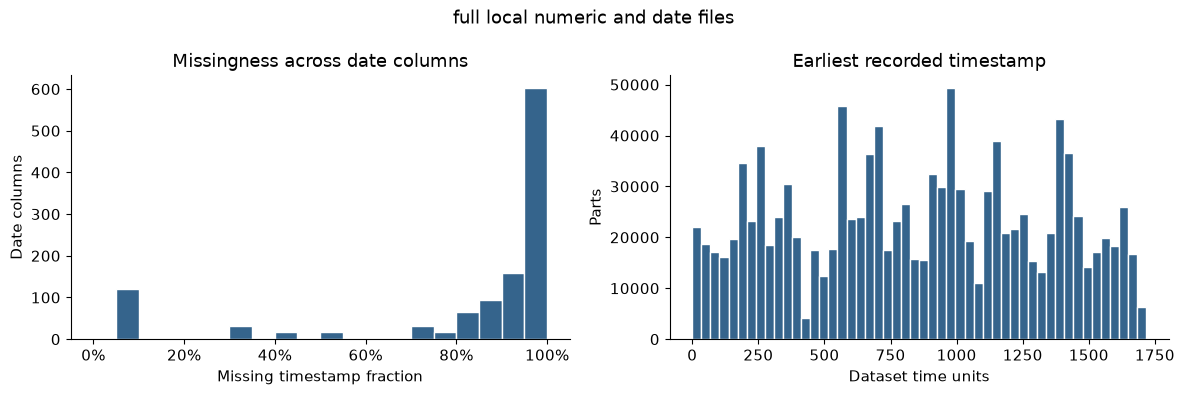

In [3]:
quality_summary = pd.Series({
    'date_columns': len(date_schema),
    'mean_column_missing_fraction': date_profile['missing_fraction'].mean(),
    'columns_all_missing': int((date_profile['recorded'] == 0).sum()),
    'zero_timestamp_cells': int(date_profile['zero_values'].sum()),
    'negative_timestamp_cells': int(date_profile['negative_values'].sum()),
    'numeric_parts_without_known_time': int(parts['date_first'].isna().sum()),
    'parts_with_zero_recorded_span': int(parts['date_span'].eq(0).sum()),
    'parts_with_positive_recorded_span': int(parts['date_span'].gt(0).sum()),
}, name='value')
display(quality_summary.to_frame())
display(parts[['date_first', 'date_last', 'date_span', 'date_measurement_count', 'date_station_count']]
        .describe(percentiles=[.01, .25, .5, .75, .99]).T)
display(station_quality.loc[list(FOCUS_STATIONS)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(date_profile['missing_fraction'], bins=np.linspace(0, 1, 21), color='#35648c', edgecolor='white')
axes[0].set(title='Missingness across date columns', xlabel='Missing timestamp fraction', ylabel='Date columns')
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].hist(parts['date_first'].dropna(), bins=50, color='#35648c', edgecolor='white')
axes[1].set(title='Earliest recorded timestamp', xlabel='Dataset time units', ylabel='Parts')
fig.suptitle(SCOPE)
plt.tight_layout()
plt.show()

### Focus-station agreement and timing gaps

Compare numeric measurement availability with date availability, without assuming they must agree. `S32_only` means **numeric** S32 recorded and numeric S33 absent, exactly as in the original project; timestamp presence does not redefine it. Historical reference counts (6,567 parts / 1,014 defective) are not used as assertions or copied into new metrics.

For parts with both stations' dates, compute `first recorded S33 − last recorded S32`. Negative values mean the recorded ranges do not fit a simple S32-then-S33 story. Without a confirmed route specification, call them signed gaps rather than invalid timestamps. No row is deleted because of a negative gap.

In [4]:
availability_rows = []
for station in FOCUS_STATIONS:
    numeric_present = parts[f'{station}_count'] > 0
    date_present = parts[f'{station}_date_first'].notna()
    availability_rows.append({'station': station,
                              'numeric_only_presence': int((numeric_present & ~date_present).sum()),
                              'date_only_presence': int((~numeric_present & date_present).sum()),
                              'both_present': int((numeric_present & date_present).sum()),
                              'both_absent': int((~numeric_present & ~date_present).sum())})
display(pd.DataFrame(availability_rows))
s32_only = ((parts['L3_S32_count'] > 0) & (parts['L3_S33_count'] == 0)).astype('uint8')
print('Numeric-defined S32_only parts in this run:', int(s32_only.sum()))
station_gap = parts['L3_S33_date_first'] - parts['L3_S32_date_last']
display(station_gap.describe(percentiles=[.01, .5, .99]).to_frame('S33_first_minus_S32_last'))
print('Negative signed gaps:', int(station_gap.lt(0).sum()), '/', int(station_gap.notna().sum()), 'observed pairs')

,station,numeric_only_presence,date_only_presence,both_present,both_absent
0,L3_S32,0,0,24543,1159204
1,L3_S33,0,0,1114695,69052
2,L3_S34,0,0,1115118,68629
3,L1_S24,0,0,183727,1000020


Numeric-defined S32_only parts in this run: 6567


,S33_first_minus_S32_last
count,17976.000000
mean,0.059398
std,0.472507
min,0.000000
1%,0.000000
50%,0.010000
99%,1.092500
max,11.910000


Negative signed gaps: 0 / 17976 observed pairs


## 4. Chronological partitions and overlap audit

Use earliest recorded time as a retrospective ordering proxy. Cut at the timestamps at approximately 64% and 80% of known-time parts. Equal first timestamps always belong to the same time window, so realized fractions can differ. Quarantine unknown times rather than invent chronology.

Remove from model fitting only those training records with last timestamp at/after validation start, and validation records with last timestamp at/after evaluation start. Keep these parts in the joined quality data and save their IDs/reasons. This conservative purge prevents **recorded observation ranges** from crossing the next boundary; it does not prove labels were available, remove all batch dependence, or undo prior exploration.

For comparison, a stratified random split uses exactly the same retained cohort. The two strategies have different evaluation parts and potentially different prevalence; differences are not a causal estimate of leakage or the isolated effect of date features.

In [5]:
chronological, exclusions, boundaries = chronological_split(parts)
random_splits = random_split_same_cohort(parts, chronological, seed=SEED)
strategies = {'random_same_cohort': random_splits, 'chronological_purged': chronological}
print('Temporal boundaries, dataset time units:', boundaries)
exclusion_summary = pd.DataFrame([
    {'reason': name, 'parts': len(rows), 'defects': int(parts['Response'].iloc[rows].sum())}
    for name, rows in exclusions.items()
])
display(exclusion_summary)
split_rows = []
for strategy, splits in strategies.items():
    for split, rows in splits.items():
        subset = parts.iloc[rows]
        split_rows.append({'strategy': strategy, 'split': split, 'parts': len(rows),
                           'defects': int(subset['Response'].sum()),
                           'prevalence': subset['Response'].mean(),
                           'first_time_min': subset['date_first'].min(),
                           'first_time_max': subset['date_first'].max(),
                           'last_time_max': subset['date_last'].max()})
split_summary = pd.DataFrame(split_rows)
display(split_summary)
np.savez_compressed(RUN_DIR / 'split_ids.npz', **{
    f'{strategy}__{split}': parts['Id'].iloc[rows].to_numpy()
    for strategy, splits in strategies.items() for split, rows in splits.items()
})
np.savez_compressed(RUN_DIR / 'excluded_ids.npz', **{
    reason: parts['Id'].iloc[rows].to_numpy() for reason, rows in exclusions.items()
})
assert parts['date_last'].iloc[chronological['train']].max() < boundaries['validation_start']
assert parts['date_last'].iloc[chronological['validation']].max() < boundaries['evaluation_start']
assert sum(len(x) for x in chronological.values()) + sum(len(x) for x in exclusions.values()) == len(parts)

Temporal boundaries, dataset time units: {'validation_start': 1046.36, 'evaluation_start': 1356.56}


,reason,parts,defects
0,unknown_dates,582,2
1,overlap_at_validation,23179,41
2,overlap_at_evaluation,2468,16


,strategy,split,parts,defects,prevalence,first_time_min,first_time_max,last_time_max
0,random_same_cohort,train,740811,4365,0.005892,0.00,1716.54,1718.48
1,random_same_cohort,validation,185203,1091,0.005891,0.01,1713.69,1718.48
2,random_same_cohort,exploratory_evaluation,231504,1364,0.005892,0.02,1713.70,1718.48
3,chronological_purged,train,734044,5282,0.007196,0.00,1046.32,1046.35
4,chronological_purged,validation,186840,574,0.003072,1046.36,1346.29,1355.96
5,chronological_purged,exploratory_evaluation,236634,964,0.004074,1356.56,1716.54,1718.48


### Training-only span diagnostics and quality decisions

Use chronological training rows to set an IQR diagnostic threshold for recorded time span. Do not clip or remove large spans: they may reflect rework, long gaps or incomplete process semantics. The first histogram retains all recorded spans; `log1p` changes only the display axis variable, not the model inputs. The threshold is not used for selection.

| Finding | Treatment | Reason / check |
|---|---|---|
| Missing or duplicate IDs / duplicate columns | Fail with an explicit error | Joining must preserve a known one-part grain |
| Unmatched numeric IDs | Preserve numeric row; report separately | Avoid silent inner-join row loss |
| All timestamps missing | Keep NaN range; quarantine from chronology | Unknown time is not time zero |
| Recorded zero or negative timestamps | Count and retain finite values | No verified physical interpretation justifies deletion |
| Infinite timestamp | Stop and investigate | Cannot define a finite recorded range |
| Multiple times in a station or negative signed interstation gap | Report; preserve | Station sequence/rework semantics are unconfirmed |
| Long recorded span | Training-only IQR flag; preserve | Statistical extremeness does not establish source error |
| Ranges crossing temporal boundaries | Exclude from temporal training/validation; save IDs | Keep recorded ranges on the correct side of each boundary |

Training-only IQR upper diagnostic bound: 33.255000000000166 dataset time units
Training span flags (retained): 108494 / 734044


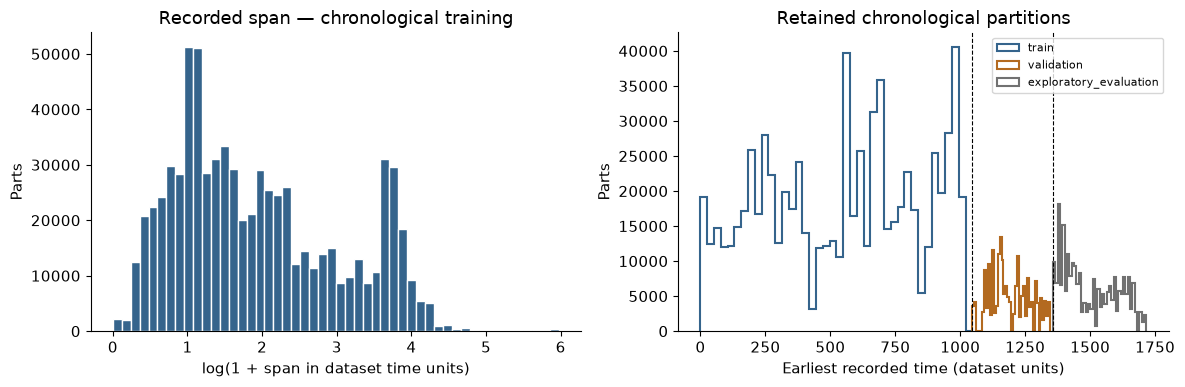

In [6]:
training_spans = parts['date_span'].iloc[chronological['train']]
q1, q3 = training_spans.quantile([.25, .75])
span_upper = float(q3 + 1.5 * (q3 - q1))
print('Training-only IQR upper diagnostic bound:', span_upper, 'dataset time units')
print('Training span flags (retained):', int(training_spans.gt(span_upper).sum()), '/', len(training_spans))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(training_spans), bins=50, color='#35648c', edgecolor='white')
axes[0].set(title='Recorded span — chronological training',
            xlabel='log(1 + span in dataset time units)', ylabel='Parts')
colors = {'train': '#35648c', 'validation': '#b36a20', 'exploratory_evaluation': '#717171'}
for split, rows in chronological.items():
    axes[1].hist(parts['date_first'].iloc[rows], bins=40, histtype='step',
                 label=split, color=colors[split], linewidth=1.5)
for boundary in boundaries.values():
    axes[1].axvline(boundary, color='black', linestyle='--', linewidth=.8)
axes[1].set(title='Retained chronological partitions', xlabel='Earliest recorded time (dataset units)', ylabel='Parts')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Fixed end-of-record experiment

Reuse the numeric count implementation and the original HGB family. No raw sensor values, S32_only, chosen focus-station timestamps, ID, join flags or target labels enter the predictors. Counts and date ranges are deterministic per-part transformations, with no fitted global imputation. HGB handles missing values natively.

For each split strategy, train two fixed candidates: numeric counts alone and the same counts plus earliest time, latest time, recorded span, recorded timestamp count and station-date count. Choose by validation AP, keeping the numeric candidate on a tie. Only that selected model is evaluated on its evaluation partition. No parameter or threshold search follows evaluation.

This is a declared new experiment. It neither reproduces nor compares directly to the historical 4.35% test AP, which used different features and split procedures. A date feature set winning on validation alone does not establish a reproducible improvement.

In [7]:
numeric_columns = tuple(c for c in parts if c.endswith('_count') and not c.startswith('date_'))
date_columns = ('date_first', 'date_last', 'date_span', 'date_measurement_count', 'date_station_count')
feature_sets = {'numeric_counts': numeric_columns, 'numeric_counts_plus_dates': numeric_columns + date_columns}
assert len(numeric_columns) == len({c.rsplit('_', 1)[0] for c in numeric_schema}) + 1
assert all('S32_only' not in columns and 'Id' not in columns and 'Response' not in columns
           for columns in feature_sets.values())
validation_results, evaluation_results, selected = run_date_experiment(
    parts, strategies, feature_sets, seed=SEED)
print('SCOPE:', SCOPE)
display(validation_results)
display(evaluation_results)
validation_results.to_csv(RUN_DIR / 'validation_results.csv', index=False)
evaluation_results.to_csv(RUN_DIR / 'exploratory_evaluation_results.csv', index=False)

SCOPE: full local numeric and date files


,strategy,feature_set,feature_count,validation_ap
0,random_same_cohort,numeric_counts,51,0.045179
1,random_same_cohort,numeric_counts_plus_dates,56,0.049885
2,chronological_purged,numeric_counts,51,0.051950
3,chronological_purged,numeric_counts_plus_dates,56,0.052426


,strategy,selected_features,parts,defects,prevalence,average_precision,capacity_requested,inspected,capacity_actual,precision,recall,f1,tn,fp,fn,tp,lift
0,random_same_cohort,numeric_counts_plus_dates,231504,1364,0.005892,0.066006,0.01,2316,0.010004,0.105354,0.178886,0.132609,228068,2072,1120,244,17.881148
1,chronological_purged,numeric_counts_plus_dates,236634,964,0.004074,0.016582,0.01,2367,0.010003,0.047740,0.117220,0.067847,233416,2254,851,113,11.718723


### Evaluation interpretation

AP is compared with each evaluation partition's own prevalence. Precision/recall and confusion counts use the prespecified highest-risk 1% policy, with ceiling rounding and stable input-order ties. The labels/parts differ between random and chronological evaluation; compare the reported support and prevalence before interpreting metric differences.

Scores from a prefix execution are software checks only. Full-file results remain retrospective and exploratory: no label-maturity timestamps, independently collected future cohort, or verified prediction-time feature availability are supplied.

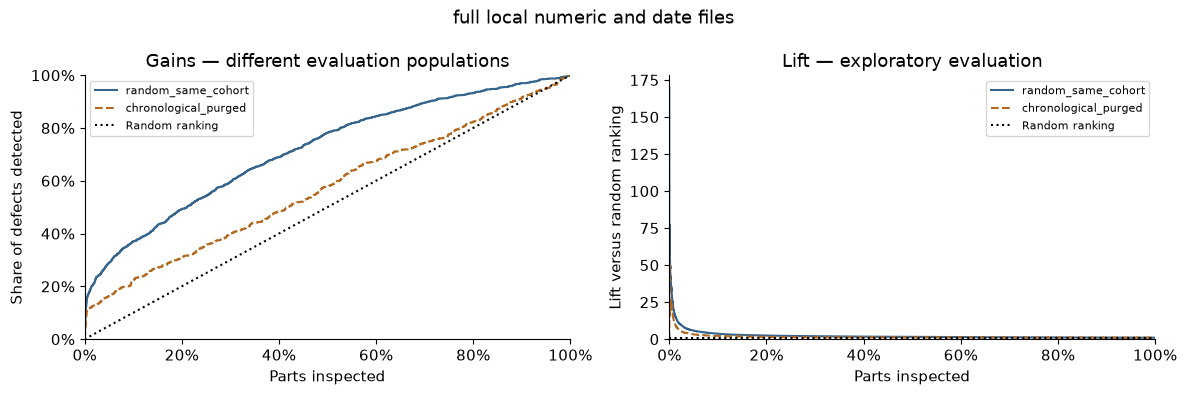

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for strategy, color, style in [('random_same_cohort', '#35648c', '-'),
                                ('chronological_purged', '#b36a20', '--')]:
    rows = strategies[strategy]['exploratory_evaluation']
    fraction, gain, lift = gains_curve(parts['Response'].iloc[rows], selected[strategy]['evaluation_scores'])
    axes[0].plot(np.r_[0, fraction], np.r_[0, gain], label=strategy, color=color, linestyle=style)
    axes[1].plot(fraction, lift, label=strategy, color=color, linestyle=style)
axes[0].plot([0, 1], [0, 1], ':', color='black', label='Random ranking')
axes[1].axhline(1, linestyle=':', color='black', label='Random ranking')
axes[0].set(title='Gains — different evaluation populations', xlabel='Parts inspected',
            ylabel='Share of defects detected', xlim=(0, 1), ylim=(0, 1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Lift — exploratory evaluation', xlabel='Parts inspected',
            ylabel='Lift versus random ranking', xlim=(0, 1), ylim=(0, None))
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
fig.suptitle(SCOPE)
plt.tight_layout()
fig.savefig(RUN_DIR / 'date_gains_lift.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Record provenance and limits

Save source context, code hashes, actual run scope, schemas, quality findings, split/exclusion IDs, model columns and newly computed metrics. File size/mtime identifies local input context but is not a full input-content checksum. Artifacts are ignored by Git and may contain source IDs; do not redistribute them as part of the dataset.

The selected models and exact schema are saved for inspection, not claimed as deployment-ready. To reproduce per-part date summaries on new data, use `summarize_date_chunk` with the saved date schema; numeric counts use the existing `build_features` with the saved sensor schema. Join by unique ID and select the saved model columns. For earlier prediction, reconstruct both inputs from an explicit as-of cutoff before computing any feature.

In [9]:
sources = {}
for name, path in [('numeric', NUMERIC_PATH), ('dates', DATE_PATH)]:
    stat = path.stat()
    sources[name] = {'path': str(path), 'bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns}
manifest = {
    'run_id': RUN_ID, 'scope': SCOPE, 'requested_nrows': N_ROWS, 'chunk_size': CHUNK_SIZE,
    'seed': SEED, 'sources': sources, 'python': platform.python_version(),
    'versions': {name: version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']},
    'code_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                   for name in ['bosch_dates.py', 'bosch.py', 'requirements.lock']},
    'notebook_source_sha256': hashlib.sha256(json.dumps([
        {'cell_type': cell['cell_type'], 'source': ''.join(cell['source'])}
        for cell in json.loads((ROOT / 'date_analysis.ipynb').read_text())['cells']
    ], sort_keys=True).encode()).hexdigest(),
    'numeric_schema': numeric_schema, 'date_schema': date_schema,
    'diagnostic_focus_stations': FOCUS_STATIONS, 'feature_sets': feature_sets,
    'join_audit': join_audit, 'date_quality': quality_summary.to_dict(),
    'temporal_boundaries': boundaries, 'exclusions': exclusion_summary.to_dict(orient='records'),
    'split_summary': split_summary.to_dict(orient='records'),
    'training_span_iqr_upper': span_upper, 'model_parameters': MODEL_PARAMETERS,
    'validation_results': validation_results.to_dict(orient='records'),
    'exploratory_evaluation_results': evaluation_results.to_dict(orient='records'),
    'independent_holdout': False, 'operational_feature_availability_verified': False,
    'time_units': 'supplied numeric dataset units; physical units unverified',
}
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
for strategy, result in selected.items():
    joblib.dump({'estimator': result['estimator'], 'columns': result['columns'],
                 'numeric_schema': numeric_schema, 'date_schema': date_schema,
                 'screening_assumption': 'all recorded inputs available before outcome is known'},
                RUN_DIR / f'{strategy}_model.joblib')
print('Saved:', RUN_DIR.relative_to(ROOT))
print('Independent validation: no. Prediction-time feature availability: unverified.')

Saved: artifacts/dates_20261029T140103667151Z
Independent validation: no. Prediction-time feature availability: unverified.


## 7. Conclusions to carry into the portfolio

Use the executed join and quality tables to explain **what was checked, what was retained, and what was excluded only from an experiment**. A perfect ID match does not imply complete timestamps. A nonnegative max-minus-min range is true by construction and is not proof that the process timestamps are correct. Station ordering, negative signed gaps and large ranges require manufacturing context.

The chronological comparison adds a more realistic stress test of recorded-time separation, while exposing additional assumptions about process overlap and label availability. It cannot undo earlier exploration. Retain the numeric-only notebook as the baseline and keep these experiment definitions and populations separate from its historical metrics.

Before a production or early-warning claim: specify the prediction event, reconstruct features using only information available then, establish when labels become known, identify batch/product grouping if available, and evaluate once on genuinely new data after freezing decisions. See [docs/date_analysis.md](docs/date_analysis.md) for reproduction and validation status.